# Citi Bike Demand Intelligence
## Entrega académica — Obtención de insights a partir de visualizaciones

**Proyecto:** Factores asociados con la demanda de bicicletas compartidas en Nueva York (2024)  
**Autor:** Lucio Benítez · **Curso:** Data Science, Coderhouse

### Abstract
Este estudio analiza **44.302.480 viajes iniciados** en el sistema Citi Bike durante 2024, integrando registros de movilidad con información meteorológica histórica de Open-Meteo. El objetivo es identificar patrones horarios, diferencias de comportamiento entre usuarios, asociaciones con el clima, variaciones estacionales y concentración de viajes por estación de origen.

**Pregunta central:** ¿Qué factores temporales, climáticos y de comportamiento están asociados con la demanda de Citi Bike y cómo pueden orientar la planificación operativa?

**Audiencia:** equipos de operaciones, planificación de movilidad, análisis de datos y estrategia. **Alcance:** investigación exploratoria y observacional; los patrones descriptivos no prueban causalidad.

> Esta versión condensa el análisis para evaluación académica. La adquisición y preparación completa están documentadas en [`notebooks/01_data_acquisition_preparation.ipynb`](https://github.com/benitezlucio/citi-bike-demand-intelligence/blob/main/notebooks/01_data_acquisition_preparation.ipynb). La versión profesional completa del EDA se conserva en [`notebooks/02_eda_insights.ipynb`](https://github.com/benitezlucio/citi-bike-demand-intelligence/blob/main/notebooks/02_eda_insights.ipynb).

## 1. Fuentes, obtención y preparación de datos

| Elemento | Descripción |
|---|---|
| **Citi Bike Trip History** | ZIP públicos con viajes iniciados en 2024; 13 columnas originales. [Fuente](https://citibikenyc.com/system-data). |
| **Open-Meteo Historical Weather API** | Temperatura, precipitación, viento, humedad y nieve, con referencia geográfica en Nueva York y zona `America/New_York`. [Fuente](https://open-meteo.com/en/docs/historical-weather-api). |
| **Procesamiento** | Descarga desde fuentes públicas, lectura por *chunks* de 250.000 registros, controles de calidad, agregaciones y cruce con clima. |
| **Integración** | Demanda a nivel hora local; tratamiento explícito de DST. La hora inexistente de marzo no se inventa; la hora repetida de noviembre se consolida. |
| **Datasets** | Horario (8.783 filas), horario segmentado (35.113 filas) y agregados por estación de origen (4.131 filas antes de consolidar IDs). |

**Reglas de calidad:** filtrar inicios dentro de 2024; excluir duraciones no positivas; no eliminar viajes largos arbitrariamente; conservar viajes sin estación de origen para los análisis no espaciales. Los 29.834 viajes sin origen válido se excluyen solamente de H6. Los archivos procesados están versionados en `data/processed/`.

## 2. Preparación reproducible y verificación

El notebook busca la raíz del repositorio automáticamente. En Colab puede clonarlo si no está presente. No requiere rutas privadas ni volver a descargar los ZIP para ejecutar las hipótesis.

In [ ]:
from pathlib import Path
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
REPO_NAME = "citi-bike-demand-intelligence"
REPO_URL = "https://github.com/benitezlucio/citi-bike-demand-intelligence.git"

def find_root(start):
    for parent in (start, *start.parents):
        for candidate in (parent, parent / REPO_NAME):
            if (candidate / "notebooks" / "01_data_acquisition_preparation.ipynb").is_file():
                return candidate
    return None

# Buscamos la raíz del proyecto en vez de depender de una ruta local fija
PROJECT_ROOT = find_root(Path.cwd().resolve())
if PROJECT_ROOT is None and "google.colab" in sys.modules:
    PROJECT_ROOT = Path("/content") / REPO_NAME
    subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Abrí el notebook desde el repositorio o usá Google Colab.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
analysis_df = pd.read_csv(PROCESSED_DIR / "citibike_analysis_hourly_2024.csv", parse_dates=["datetime"])
segmented_df = pd.read_csv(PROCESSED_DIR / "citibike_segmented_hourly_2024.csv", parse_dates=["datetime"])
stations_df = pd.read_csv(PROCESSED_DIR / "citibike_stations_2024.csv")
print("Ruta de datos:", PROCESSED_DIR)

In [ ]:
# Validamos que las tres tablas conserven los totales originales
assert analysis_df.shape[0] == 8783
assert analysis_df["ride_count"].sum() == 44_302_480
assert segmented_df["ride_count"].sum() == 44_302_480
assert stations_df["ride_count"].sum() == 44_272_646
assert analysis_df["datetime"].is_unique
assert analysis_df.isna().sum().sum() == 0

print("Analysis:", analysis_df.shape, "| Segmented:", segmented_df.shape, "| Stations:", stations_df.shape)
print("Fechas:", analysis_df.datetime.min(), "→", analysis_df.datetime.max())
print("Viajes:", f'{analysis_df.ride_count.sum():,}')
print("Validaciones correctas")

## 3. Preguntas e hipótesis

| ID | Pregunta | Hipótesis inicial |
|---|---|---|
| **H1** | ¿Hay franjas con mayor demanda? | Picos en horarios compatibles con commuting. |
| **H2** | ¿Cambian los patrones entre laborables y fines de semana? | Mayor concentración en horas laborales; perfil más gradual los fines de semana. |
| **H3** | ¿Difieren members y casuals? | Members más vinculados con jornadas laborales; casuals más activos en fines de semana. |
| **H4** | ¿Cómo se relaciona el clima con la demanda? | Precipitación, temperaturas extremas y vientos intensos asociados con menor utilización. |
| **H5** | ¿Existe estacionalidad? | Mayor uso en meses cálidos y menor uso en invierno. |
| **H6** | ¿Los viajes se concentran en pocas estaciones de origen? | Una proporción reducida de estaciones concentra gran parte de las salidas. |

**Metodología:** análisis descriptivo y visual por hipótesis, interpretación con métricas reales y veredicto (*apoyada*, *parcialmente apoyada* o *no apoyada*). Se mantienen explícitas las limitaciones observacionales.

## 4. H1 — Horario de la demanda

Se compara la media, mediana y dispersión de viajes iniciados por hora local. La media permite construir un perfil diario comparable sin sumar días indiscriminadamente.

In [ ]:
# Calculamos el perfil promedio por hora; después identificamos los picos
hourly_profile = (analysis_df.groupby("hour")["ride_count"]
                  .agg(average_rides="mean", median_rides="median", std_rides="std")
                  .reset_index())
peak = hourly_profile.loc[hourly_profile.average_rides.idxmax()]
low = hourly_profile.loc[hourly_profile.average_rides.idxmin()]
print("Máximo:", int(peak.hour), "h |", round(peak.average_rides), "viajes")
print("Mínimo:", int(low.hour), "h |", round(low.average_rides), "viajes")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hourly_profile.hour, hourly_profile.average_rides, marker="o", linewidth=2.2)
ax.set(xlabel="Hora del día", ylabel="Viajes iniciados por hora (promedio)",
       title="H1 · Demanda horaria promedio de Citi Bike")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

**Referencia visual de la ejecución validada.** Perfil horario validado: máximo local a las 08:00 y máximo global a las 17:00.

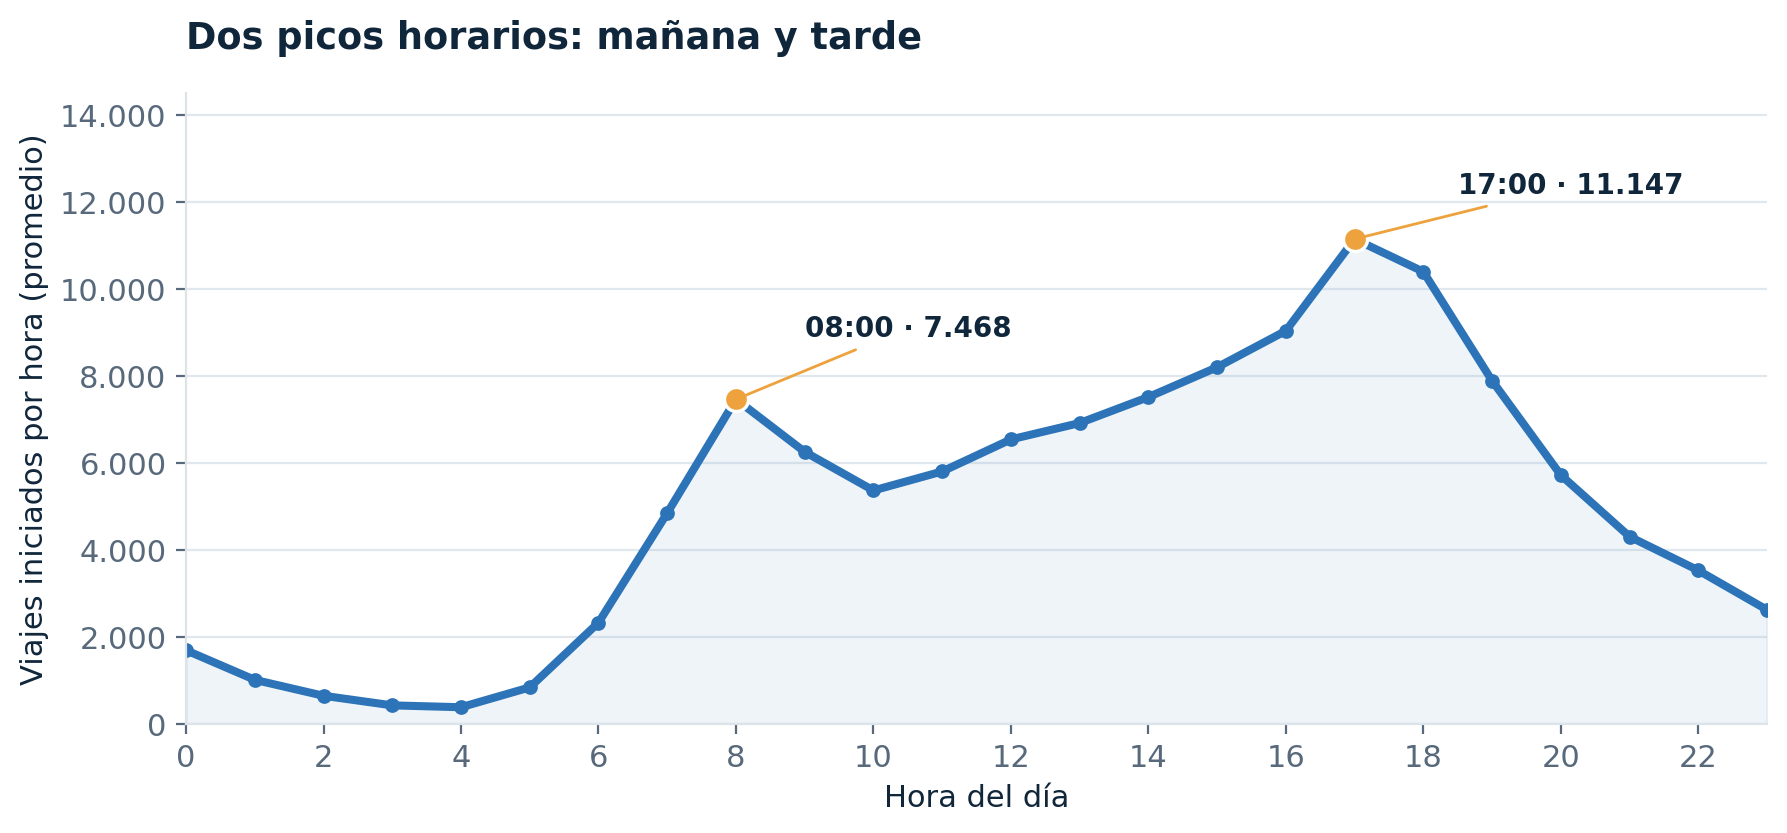

**H1 · Parcialmente apoyada.** La demanda alcanza **7.468 viajes/h a las 08:00** y **11.147 a las 17:00**. El máximo de las 17:00 supera en **121%** al promedio general y es **28,2 veces** el mínimo de las 04:00. Los picos son compatibles con commuting, pero no contamos con el motivo registrado de cada viaje.

## 5. H2 — Días laborales vs. fines de semana

Comparamos perfiles horarios separados por tipo de día. También normalizamos cada curva como proporción del perfil diario promedio para distinguir **volumen** de **forma**.

In [ ]:
# Un día laborable no es lo mismo que un fin de semana, así que calculamos curvas separadas
h2_hourly = (analysis_df.groupby(["is_weekend", "hour"])["ride_count"]
             .mean().unstack("is_weekend").rename(columns={False:"weekday", True:"weekend"}))
h2_pct = h2_hourly.div(h2_hourly.sum(axis=0), axis=1) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, label in [("weekday", "Laborables"), ("weekend", "Fin de semana")]:
    axes[0].plot(h2_hourly.index, h2_hourly[name], label=label, linewidth=2)
    axes[1].plot(h2_pct.index, h2_pct[name], label=label, linewidth=2)
axes[0].set(title="Viajes/hora (promedio)", xlabel="Hora")
axes[1].set(title="% del perfil diario", xlabel="Hora")
axes[0].legend(frameon=False)
for ax in axes: ax.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.show()

**Referencia visual de la ejecución validada.** Curvas validadas: dos picos laborables frente a una demanda de fin de semana más gradual.

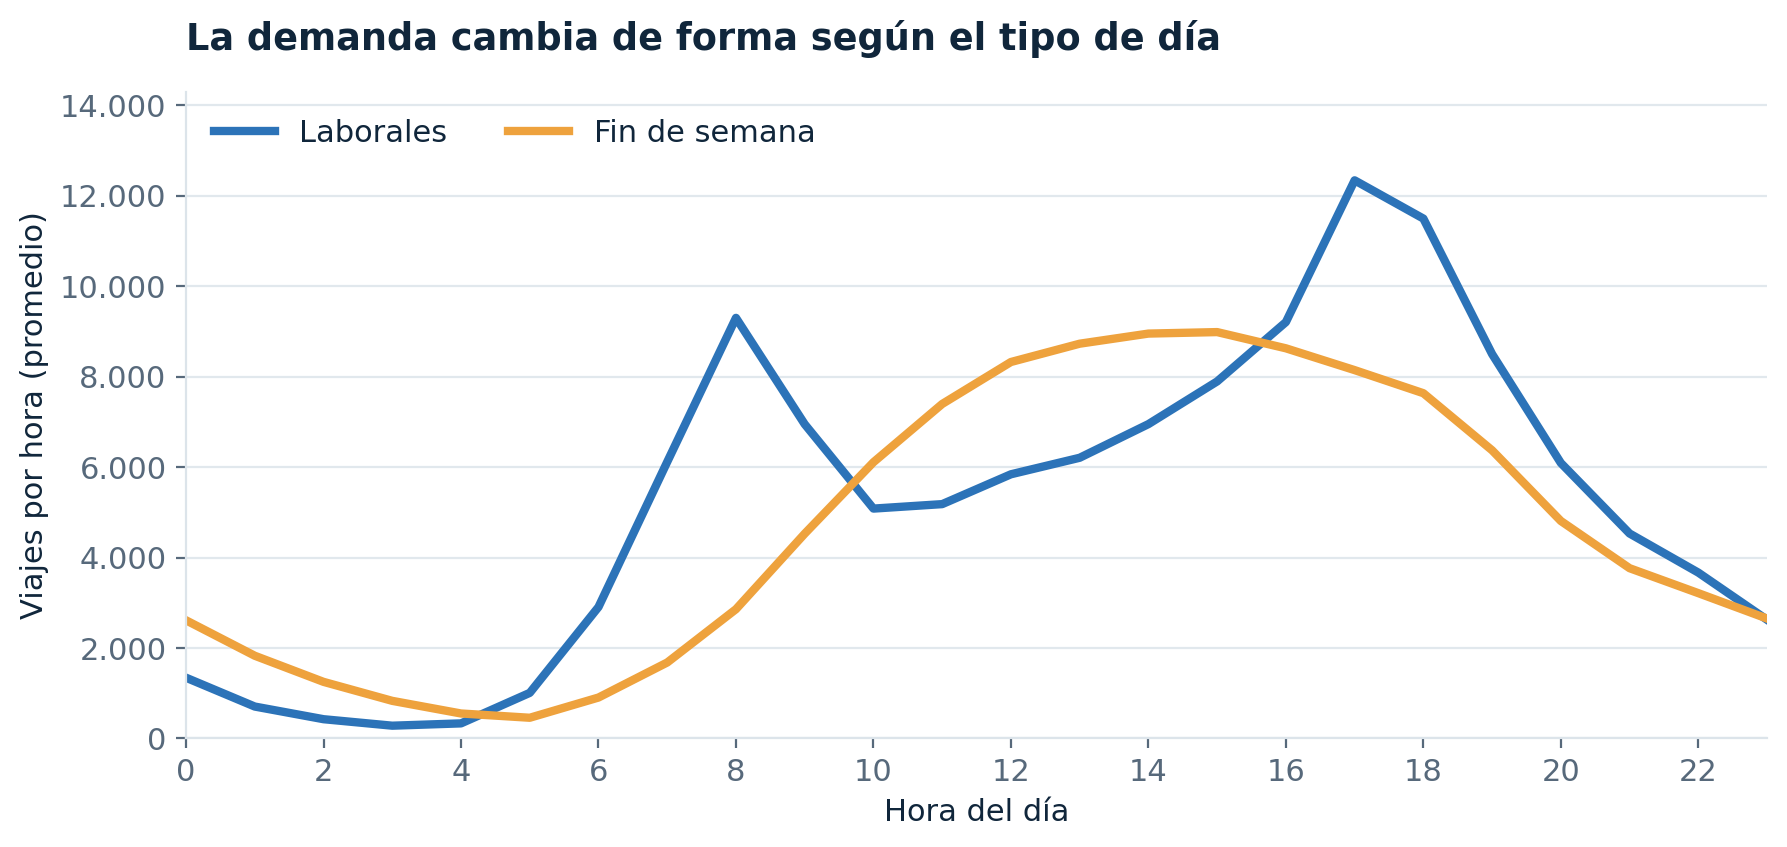

**H2 · Apoyada.** Los días laborales alcanzan **9.298 viajes/h a las 08:00** y **12.339 a las 17:00**. El fin de semana tiene su máximo a las **15:00 (8.984 viajes/h)**. Entre las 12:00 y las 16:00 se concentra **28,89%** del perfil laboral, frente a **39,22%** del de fines de semana. No se excluyeron feriados del grupo lunes–viernes.

## 6. H3 — Diferencias entre Member y Casual

La tabla segmentada tiene filas por tipo de usuario **y** tipo de bicicleta. Para evitar promediar medias de subsegmentos incorrectamente, primero sumamos classic y electric por `datetime × member_casual`.

In [ ]:
# Sumamos los tipos de bici dentro de cada tipo de usuario y hora
h3_user_demand = (segmented_df.groupby(["datetime", "member_casual"])["ride_count"]
                  .sum().unstack(fill_value=0).reindex(analysis_df["datetime"], fill_value=0))
assert np.array_equal(h3_user_demand.sum(axis=1).to_numpy(), analysis_df["ride_count"].to_numpy())
h3_hourly_avg = h3_user_demand.groupby(h3_user_demand.index.hour).mean()[["member", "casual"]]
h3_hourly_pct = h3_hourly_avg.div(h3_hourly_avg.sum(axis=0), axis=1) * 100

# Contamos cuántos días hay de cada tipo para comparar demanda diaria, no totales acumulados
h3_day_type = h3_user_demand.join(analysis_df.set_index("datetime")["is_weekend"])
days = analysis_df.groupby("is_weekend")["date"].nunique()
h3_daily_avg = h3_day_type.groupby("is_weekend")[["member", "casual"]].sum().div(days, axis=0)
h3_share = h3_daily_avg.div(h3_daily_avg.sum(axis=1), axis=0) * 100
print("Viajes diarios promedio:\n", h3_daily_avg.round(1))
print("Participación (%):\n", h3_share.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
for c in ["member", "casual"]:
    ax.plot(h3_hourly_pct.index, h3_hourly_pct[c], linewidth=2, label=c.capitalize())
ax.set(xlabel="Hora", ylabel="% del perfil diario", title="H3 · Distribución horaria por usuario")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Referencia visual de la ejecución validada.** Perfiles horarios validados de members y usuarios ocasionales.

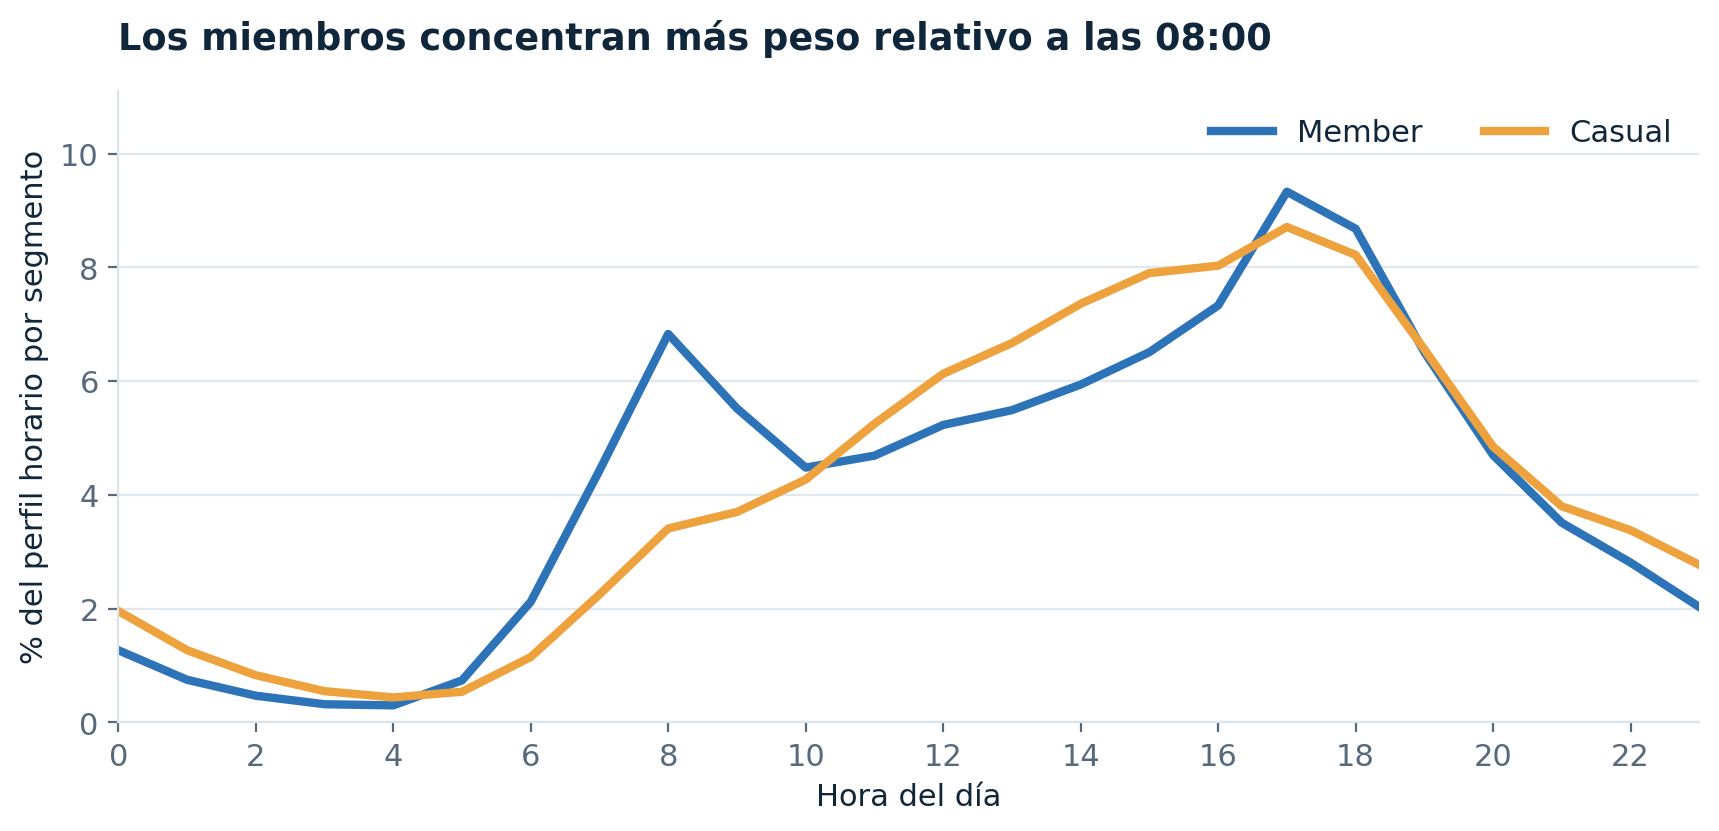

**H3 · Apoyada.** Los members representan el **80,7%** de viajes. Su demanda diaria es **21,18% menor los fines de semana**, mientras que la de casuals es **39,14% mayor**. La participación casual pasa de **16,84%** en días laborales a **26,33%** en fines de semana. Los patrones son compatibles con usos distintos, pero no prueban viajes recreativos o laborales.

## 7. H4 — Condiciones meteorológicas

Estudiamos primero una comparación **bruta** entre horas con/sin precipitación y luego una comparación **estratificada** por mes, hora y tipo de día. Para temperatura y viento se calculan correlaciones de Pearson sobre horas secas antes y después de descontar promedios temporales del grupo.

In [ ]:
# Comparación general de demanda con y sin precipitación
precip = analysis_df.groupby("has_precipitation")["ride_count"].agg(["size", "mean", "median"])
dry_avg, wet_avg = precip.loc[False, "mean"], precip.loc[True, "mean"]
raw_diff_pct = (wet_avg / dry_avg - 1) * 100

# Emparejamos mes, hora y tipo de día. Sólo comparamos donde hay casos secos y húmedos
keys = ["month_num", "hour", "is_weekend"]
groups = analysis_df.groupby(keys + ["has_precipitation"])["ride_count"].agg(avg="mean", n="size").reset_index()
dry = groups[~groups.has_precipitation].rename(columns={"avg":"dry_avg", "n":"dry_n"})
wet = groups[groups.has_precipitation].rename(columns={"avg":"wet_avg", "n":"wet_n"})
matched = dry.merge(wet, on=keys)
matched = matched[(matched.dry_n >= 2) & (matched.wet_n >= 2)].copy()
weights = np.minimum(matched.dry_n, matched.wet_n)
strat_dry = np.average(matched.dry_avg, weights=weights)
strat_wet = np.average(matched.wet_avg, weights=weights)
strat_diff_pct = (strat_wet / strat_dry - 1) * 100
print(f"Precipitación: {raw_diff_pct:.2f}% bruta, {strat_diff_pct:.2f}% estratificada")
print("Grupos comparables:", len(matched), "| Cobertura húmeda:",
      round(100 * matched.wet_n.sum() / analysis_df.has_precipitation.sum(), 1), "%")

In [ ]:
# Medimos cuánto se aleja cada hora seca del promedio de su grupo temporal
weather_dry = analysis_df.loc[~analysis_df.has_precipitation].copy()
keys = ["month_num", "hour", "is_weekend"]
for variable in ["temperature_2m", "wind_speed_10m"]:
    mean_by_group = weather_dry.groupby(keys)[[variable, "ride_count"]].transform("mean")
    weather_dry[f"{variable}_anomaly"] = weather_dry[variable] - mean_by_group[variable]
    weather_dry[f"rides_anomaly_{variable}"] = weather_dry.ride_count - mean_by_group.ride_count
    raw = weather_dry[variable].corr(weather_dry.ride_count)
    adjusted = weather_dry[f"{variable}_anomaly"].corr(weather_dry[f"rides_anomaly_{variable}"])
    print(f"{variable}: original={raw:.3f} | ajustada={adjusted:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(["Sin precipitación", "Con precipitación"], [dry_avg, wet_avg], color=["#2C73B8", "#EEA23D"])
ax.set(ylabel="Viajes iniciados/hora", title="H4 · Menor demanda durante precipitaciones")
plt.tight_layout(); plt.show()

**Referencia visual de la ejecución validada.** Comparaciones validadas: precipitación, temperatura y viento con ajuste temporal.

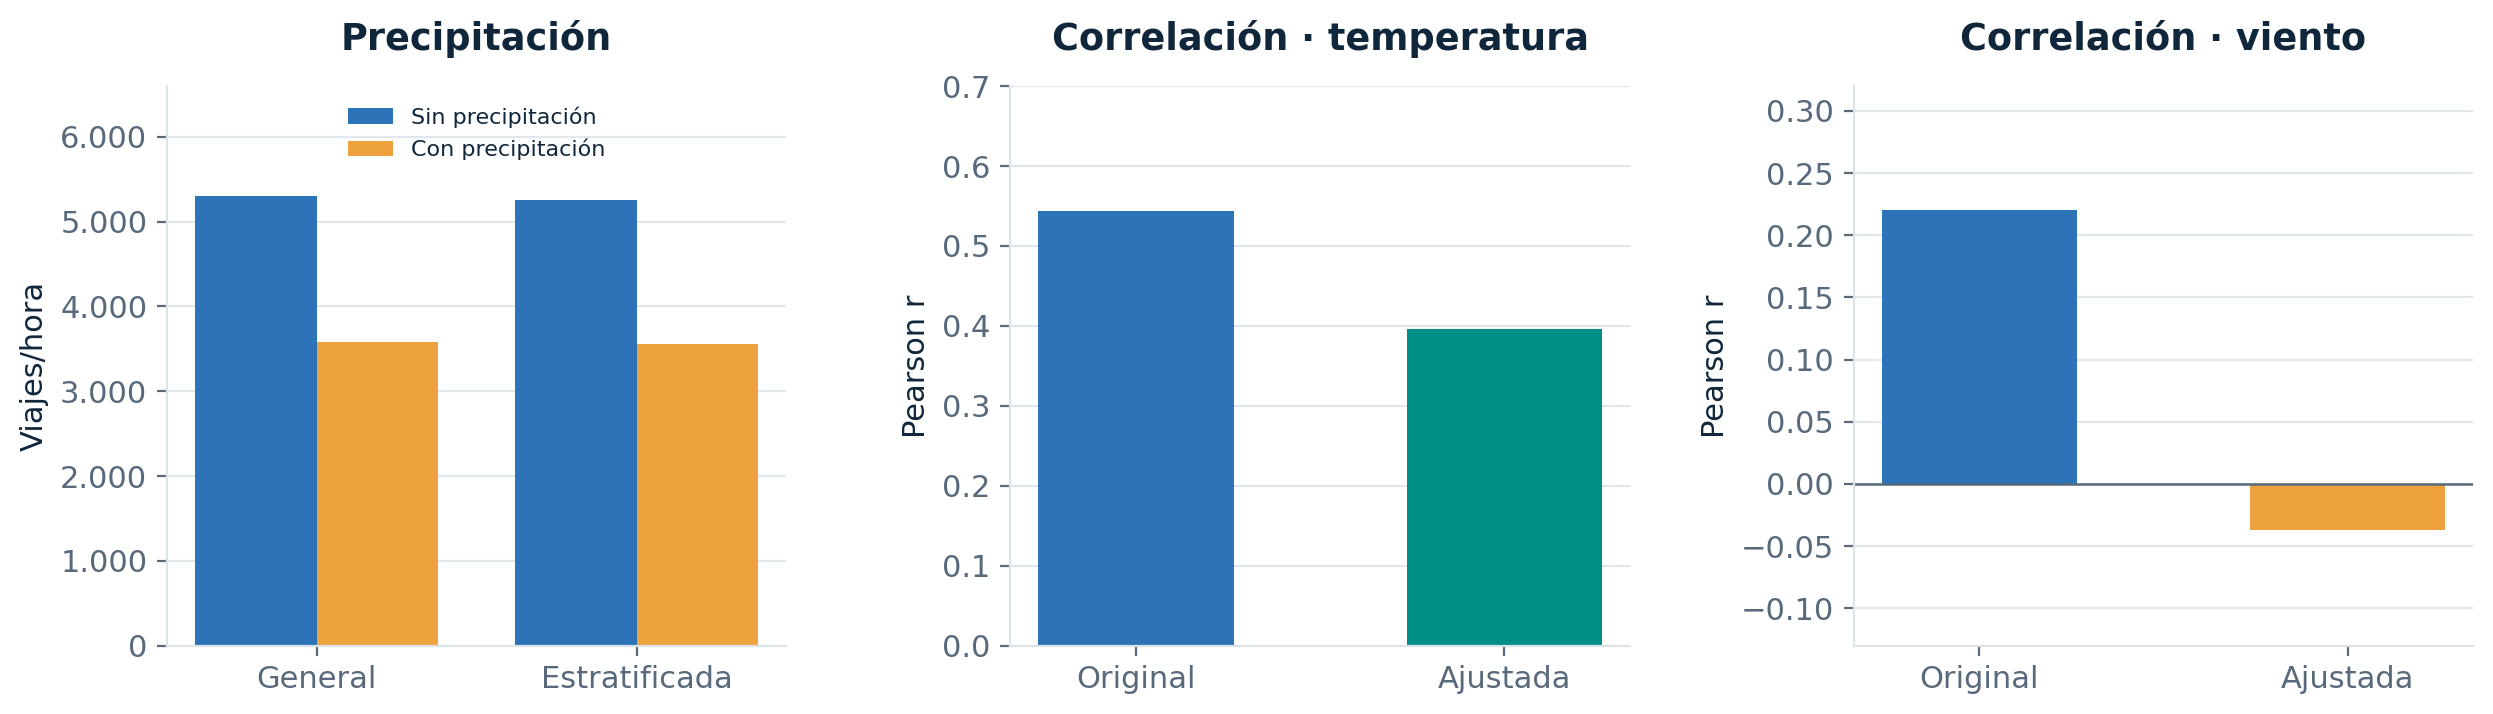

**H4 · Parcialmente apoyada.** Las horas con precipitación tienen **32,43% menos viajes** en bruto y **32,46% menos** en la comparación estratificada (343 grupos; 90% de cobertura de horas con precipitación). Temperatura: correlación ajustada **+0,396**; viento: **−0,037**. La evidencia respalda menor demanda con precipitación y frío, pero no una relación lineal negativa relevante con viento ni caída demostrada por calor extremo. Asociación ≠ causalidad.

## 8. H5 — Estacionalidad

Comparamos **demanda diaria promedio** por mes para no confundir diferencias de uso con la cantidad de días de cada mes. Luego calculamos resúmenes por estación meteorológica: Winter (dic–feb), Spring (mar–may), Summer (jun–ago), Autumn (sep–nov).

In [ ]:
# Primero sumamos viajes por día, después calculamos promedios mensuales
by_day = (analysis_df.assign(date=analysis_df.datetime.dt.normalize())
          .groupby("date", as_index=False)["ride_count"].sum())
by_day["month_num"] = by_day.date.dt.month
month = by_day.groupby("month_num")["ride_count"].agg(days="size", total="sum", daily_avg="mean", daily_median="median")
assert len(by_day) == 366 and month.total.sum() == 44_302_480
print(month.round(1))

season_map = analysis_df.assign(date=analysis_df.datetime.dt.normalize()).groupby("date")["season"].first()
by_day["season"] = by_day.date.map(season_map)
season = by_day.groupby("season")["ride_count"].agg(days="size", daily_avg="mean", daily_median="median")
print("\nDemanda por estación:\n", season.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(month.index, month.daily_avg, marker="o", linewidth=2)
ax.set(xlabel="Mes", ylabel="Viajes diarios (promedio)", title="H5 · Evolución mensual de la demanda")
ax.set_xticks(range(1,13)); plt.tight_layout(); plt.show()

**Referencia visual de la ejecución validada.** Demanda media diaria mensual validada durante 2024.

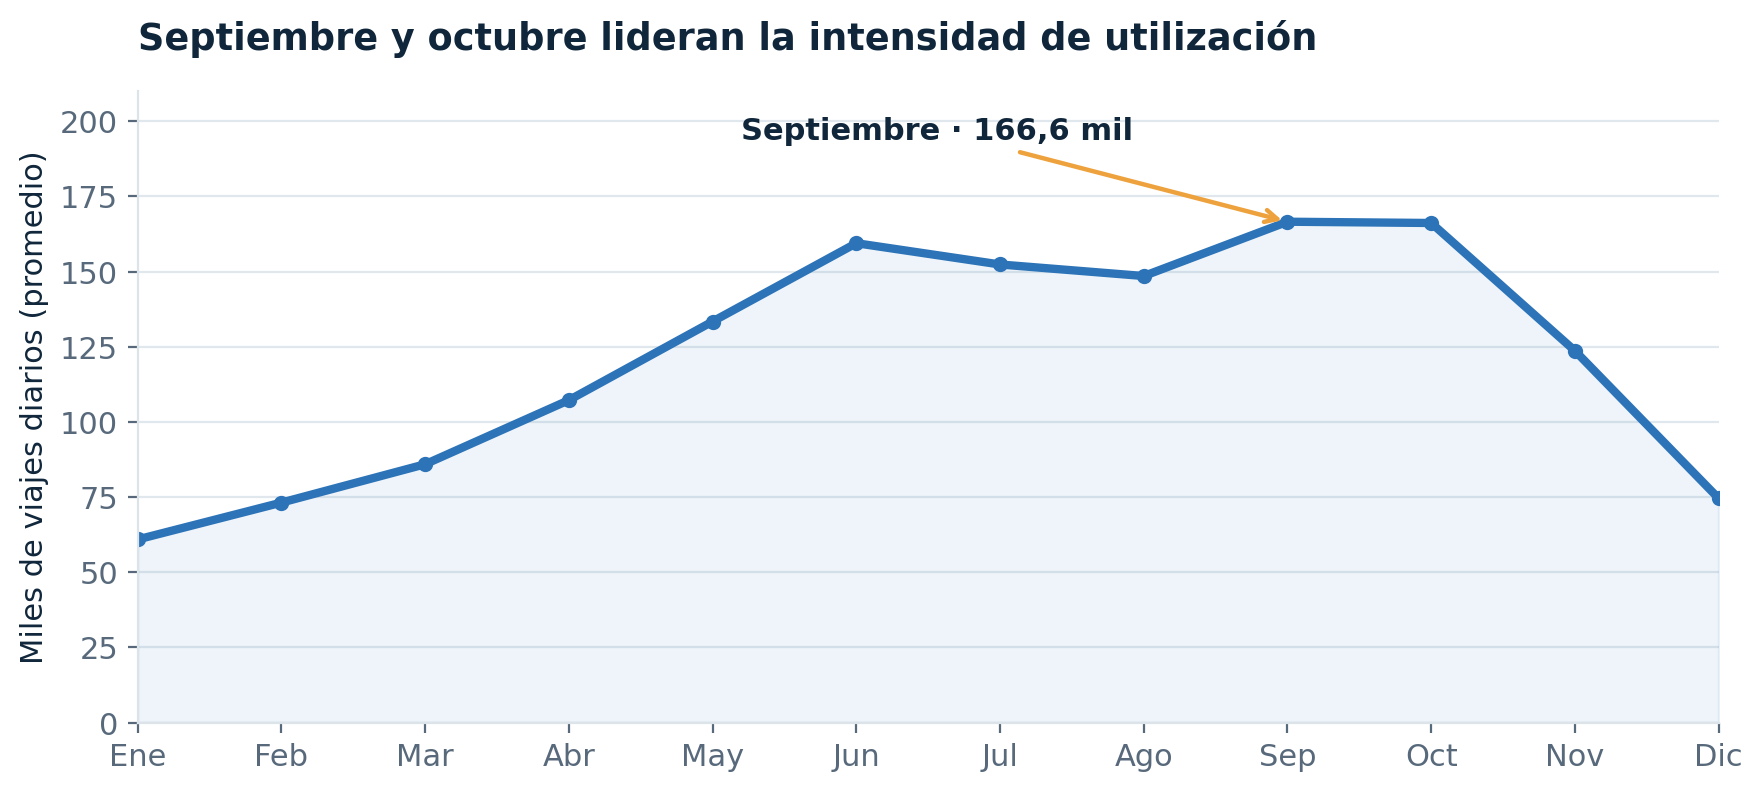

**H5 · Apoyada.** El promedio diario de verano (**153.368 viajes**) supera en **120,8%** al de invierno (**69.454**). **Septiembre** tiene el mayor promedio mensual (**166.576 viajes/día**); **octubre**, el mayor total mensual. Un solo año no permite demostrar estacionalidad plurianual, ni atribuir todo el patrón al clima.

## 9. H6 — Concentración de viajes por estación de origen

El CSV contiene **4.131 filas**, pero sólo **2.378 IDs únicos**. Hay agregados parciales repetidos; se **suman** viajes por `start_station_id` en vez de eliminar duplicados. Algunos IDs registran distintos nombres; por lo tanto, hablamos de identificadores, no necesariamente de localizaciones físicas únicas.

In [ ]:
# Reagrupamos por ID porque el CSV trae varias filas para algunas estaciones
stations_h6 = (stations_df.groupby("start_station_id", as_index=False)["ride_count"]
               .sum().sort_values("ride_count", ascending=False).reset_index(drop=True))
assert stations_h6.start_station_id.is_unique
assert stations_h6.ride_count.sum() == 44_272_646
n = len(stations_h6)
all_rides = stations_h6.ride_count.sum()
share10 = stations_h6.head(int(np.ceil(.10*n))).ride_count.sum() / all_rides * 100
share20 = stations_h6.head(int(np.ceil(.20*n))).ride_count.sum() / all_rides * 100
cum = stations_h6.ride_count.cumsum() / all_rides
half = int((cum < .5).sum() + 1)

# La curva de Lorenz arranca por las estaciones con menos viajes
values = np.sort(stations_h6.ride_count.to_numpy())
x = np.arange(n+1) / n
y = np.insert(np.cumsum(values) / values.sum(), 0, 0)
gini = 1 - 2 * np.trapezoid(y, x)
print(f"Top 10%: {share10:.2f}% | Top 20%: {share20:.2f}%")
print(f"IDs para el 50%: {half} ({half/n*100:.2f}%) | Gini: {gini:.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(x, y, linewidth=2.5, label="Observada")
ax.plot([0,1],[0,1],"--",color="gray",label="Igualdad")
ax.fill_between(x,y,x,alpha=.12)
ax.set(xlabel="Proporción acumulada de IDs",ylabel="Proporción acumulada de viajes",title="H6 · Curva de Lorenz")
ax.legend(frameon=False);plt.tight_layout();plt.show()

**Referencia visual de la ejecución validada.** Curva de Lorenz de la ejecución validada (Gini = 0,599).

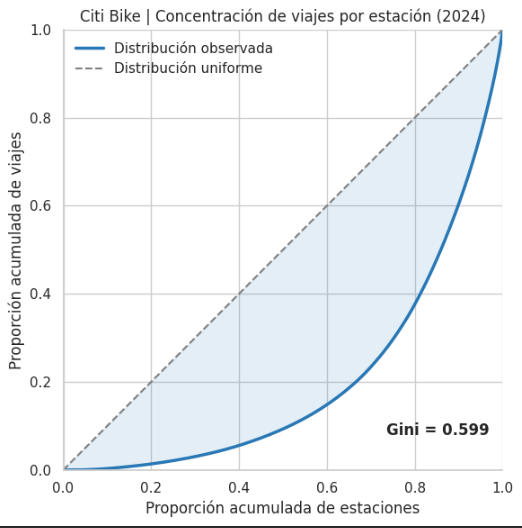

**H6 · Apoyada.** El **10% de los IDs** concentra **39,67%** de los viajes; el **20%**, **62,44%**. Sólo **335 IDs (14,09%)** concentran la mitad de las salidas. El **Gini es 0,599**. Esto sugiere priorizar estudios de capacidad en ciertos puntos, pero las salidas por sí solas no prueban escasez de bicicletas.

## 10. Insights integrados y decisiones posibles

| Insight integrado | Evidencia | Decisión a evaluar |
|---|---|---|
| **Planeamiento por horario y día** | Picos laborales 08:00 y 17:00; perfil de fin de semana más gradual | Diferenciar ventanas operativas según día de la semana. |
| **Segmentación de usuarios** | Member −21,18% y casual +39,14% en fines de semana | Analizar disponibilidad y estrategias comerciales por perfil. |
| **Clima como variable operativa** | Precipitación −32,46% tras estratificar | Probar pronósticos meteorológicos para escenarios de demanda. |
| **Capacidad estacional** | Verano +120,8% vs. invierno; septiembre/octubre muy activos | Planificar capacidad y mantenimiento por período anual. |
| **Concentración espacial** | Top 20% de IDs = 62,44% de salidas | Priorizar auditorías de estaciones de mayor uso, incorporando llegadas y capacidad. |

Estos son **criterios para evaluar** decisiones, no evidencia de intervenciones ya implementadas.

## 11. Conclusiones y próximos pasos

El uso de Citi Bike durante 2024 muestra patrones **temporales**, **de composición de usuarios**, **meteorológicos** y **espaciales** relevantes para comprender la demanda. Se analizaron seis hipótesis: **cuatro apoyadas y dos parcialmente apoyadas**. La conclusión central es que no basta con un promedio general: la intensidad y distribución de la demanda cambia según cuándo, bajo qué condiciones y desde dónde se inicia el viaje.

### Limitaciones
- **Un solo año** de observaciones; no es evidencia de patrones plurianuales.
- Relaciones **observacionales**: no se identifica propósito de viaje ni causalidad meteorológica.
- Condiciones climáticas de **un punto de referencia** y no de cada estación.
- **H6 considera salidas**, sin entradas, capacidad, ocupación ni inventario; los IDs no necesariamente son ubicaciones físicas únicas.
- Pocas observaciones de nieve y temperaturas mayores de 35 °C.

### Evolución hacia Machine Learning
1. Definir **horizonte predictivo** y variables conocidas al momento de pronosticar.
2. Construir un **baseline** temporal y validar cronológicamente.
3. Comparar modelos de regresión con **MAE y RMSE**.
4. Medir el aporte del clima contra un baseline sólo calendario.
5. Evitar *data leakage*: no usar clima futuro observado si no estaría disponible en producción.

**Reproducibilidad:** esta entrega utiliza los mismos tres CSV versionados que el notebook profesional; los resultados y gráficos se pueden regenerar ejecutando las celdas. Las imágenes de referencia insertadas provienen de análisis previamente validados y no sustituyen la ejecución del código.